# CSE303 Capstone: Explainable and Cost-Sensitive E-Commerce Fraud Detection
## Stage 1: Memory-Conscious Exploratory Data Analysis (EDA) Starter Notebook

**Dataset Source:** [https://www.kaggle.com/competitions/ieee-fraud-detection/data](https://www.kaggle.com/competitions/ieee-fraud-detection/data)  
**Target Variable:** `isFraud` (`0 = Legitimate`, `1 = Fraudulent`)

---

### 1. Project Objective & Problem Framing for ML Students

In introductory machine learning, classification tasks typically feature balanced classes and treat every classification error with equal penalty. In **e-commerce payment fraud detection**, two core complexities alter how models must be evaluated:

1. **Severe Class Imbalance:**
   - Fraudulent transactions represent a small minority of transactions in real-world payment streams.
   - A naive baseline classifier that predicts "Legitimate" for 100% of transactions can report a deceptively high raw accuracy score while failing to detect a single fraud event.
   - Therefore, performance must be evaluated using metrics designed for imbalanced data, such as Precision, Recall, Confusion Matrices, and PR-AUC.

2. **Asymmetric Error Costs (Cost-Sensitivity):**
   - **False Negative (FN):** The model predicts legitimate, but the transaction was fraudulent. This results in direct financial loss, dispute fees, and chargeback penalties.
   - **False Positive (FP):** The model predicts fraud, but the transaction was legitimate. This introduces customer friction, potential cart abandonment, and administrative review costs.
   - *Hypothetical Illustration:* For pedagogical intuition, one might hypothetically assume an undetected fraud incurs a $500 loss while reviewing a false alert costs $5. **Important Notice:** These figures are strictly hypothetical illustrations for conceptual clarity, not verified facts. Formal cost-sensitive optimization will only be claimed once a specific, domain-justified cost matrix is explicitly defined in Stage 4.

3. **Interpretability & Decision Trees:**
   - Financial and risk compliance requires transparent explanations for transaction flags.
   - In this capstone, our first modeling milestone will use **Decision Trees**, allowing us to inspect split criteria, tree depth, and feature importance before evaluating more complex algorithms.

--- 
## 2. Import Libraries
We import foundational data science libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `os`, `pathlib`).

In [ ]:
import os
from pathlib import Path

# Core numerical and tabular manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Configure readable, clean plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Libraries successfully imported!")

--- 
## 3. Dataset Verification & Memory-Conscious Inspection

The IEEE-CIS dataset files are large tabular datasets that expand significantly in RAM when parsed by `pandas`. Rather than assuming unverified file sizes, we use the file-size inspection code below to check on-disk sizes directly.

To keep our workflow efficient and prevent memory exhaustion on local machines:
1. We verify whether the dataset files exist and check their on-disk file sizes.
2. If files are missing, the notebook provides helpful instructions on where to place them without downloading anything automatically.
3. We inspect each table individually before attempting any merges.
4. We load the **first 10,000 rows** (`nrows=10000`) for preliminary structural and schema inspection.

> **Crucial Methodological Distinction on Data Loading:**  
> The 10,000 rows loaded in this notebook are the **first 10,000 rows**, NOT a random sample. This slice is strictly intended for initial **structural and schema inspection** (checking column names, data types, and null formats).  
> - Because the dataset is chronologically ordered by `TransactionDT`, this sequential slice **may be biased by transaction ordering**.
> - **Do not treat its fraud percentage, missingness rates, or feature distributions as representative of the full dataset.**  
> - The exact full-training-label distribution can be calculated later using a memory-conscious approach (such as reading only the target column via `usecols=['isFraud']` or processing in chunks) without loading all feature columns.

In [ ]:
# Determine relative path to raw data directory
DATA_DIR = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
TRAIN_TRANS_PATH = DATA_DIR / "train_transaction.csv"
TRAIN_ID_PATH = DATA_DIR / "train_identity.csv"

def inspect_file(file_path):
    """Checks file existence and reports size in MB and GB directly from disk."""
    if file_path.exists():
        size_bytes = file_path.stat().st_size
        size_mb = size_bytes / (1024 ** 2)
        size_gb = size_bytes / (1024 ** 3)
        print(f"[FOUND] {file_path.name} | Size: {size_mb:,.2f} MB ({size_gb:.2f} GB)")
        return True
    else:
        print(f"[MISSING] {file_path.name} (not found in {file_path.parent.resolve()})")
        return False

print(f"Checking data directory: {DATA_DIR.resolve()}\n")
trans_available = inspect_file(TRAIN_TRANS_PATH)
id_available = inspect_file(TRAIN_ID_PATH)

if not trans_available or not id_available:
    print("\n" + "="*70)
    print("ACTION REQUIRED: Dataset files are not present in data/raw/")
    print("="*70)
    print("1. Download the labeled dataset manually from Kaggle:")
    print("   https://www.kaggle.com/competitions/ieee-fraud-detection/data")
    print("2. Extract and place 'train_transaction.csv' and 'train_identity.csv' into:")
    print(f"   {DATA_DIR.resolve()}")
    print("3. Once the files are in place, re-run this notebook to inspect actual data.")
    print("="*70)

### Memory-Conscious Structural Inspection (First 10,000 Rows)
When working with large tabular datasets in `pandas`:
- Reading entire files without options can consume significant RAM due to default 64-bit data types (`float64`, `int64`, `object`).
- We use `nrows=SAMPLE_SIZE` to load the first 10,000 rows to safely inspect column names, data types, and dataframe structures.
- **Note on Sampling Bias:** Because this loads sequential rows from the start of the file, this slice may be biased by transaction ordering. It is solely for structural verification, not for drawing final statistical inferences about the full population.
- We use `df.info(memory_usage='deep')` and memory tracking to monitor in-memory consumption.

In [ ]:
# Slice size for preliminary structural inspection (first 10,000 rows)
SAMPLE_SIZE = 10000

def load_initial_slice(file_path, sample_rows=SAMPLE_SIZE):
    """Loads the first N rows from a CSV to safely inspect structure and schema."""
    if not file_path.exists():
        return None
    print(f"Loading first {sample_rows:,} sequential rows of {file_path.name}...")
    df = pd.read_csv(file_path, nrows=sample_rows)
    mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns. In-memory size: ~{mem_mb:.2f} MB")
    return df

df_trans_sample = load_initial_slice(TRAIN_TRANS_PATH, SAMPLE_SIZE) if trans_available else None
df_id_sample = load_initial_slice(TRAIN_ID_PATH, SAMPLE_SIZE) if id_available else None

--- 
## 4. Individual Table Inspection & Understanding `TransactionID`

Before performing any join or merge, we inspect each table independently to understand what entities they represent.

### The `TransactionID` Relationship:
- **`train_transaction.csv`:** Contains financial transaction records (payment amount, card info, product code, timestamps). Every row represents an attempted transaction with a unique primary key `TransactionID`.
- **`train_identity.csv`:** Contains identity, device, and network telemetry (IP, DeviceType, browser, operating system). **Identity records are available for only a subset of transactions.** Not every transaction has a corresponding identity record.
- **Why we do NOT merge the full tables right now:** Merging hundreds of thousands of rows across hundreds of columns increases memory footprint dramatically. We first inspect columns and missingness individually.

In [ ]:
print("=== Transaction Table Initial Slice Inspection ===")
if df_trans_sample is not None:
    print(f"Slice Shape (First {len(df_trans_sample):,} rows): {df_trans_sample.shape}")
    print("\nFirst 3 rows:")
    display(df_trans_sample.head(3))
    print("\nColumn Data Types Summary:")
    print(df_trans_sample.dtypes.value_counts())
else:
    print("Transaction data not loaded (file not found in data/raw/).")

In [ ]:
print("=== Identity Table Initial Slice Inspection ===")
if df_id_sample is not None:
    print(f"Slice Shape (First {len(df_id_sample):,} rows): {df_id_sample.shape}")
    print("\nFirst 3 rows:")
    display(df_id_sample.head(3))
    print("\nColumn Data Types Summary:")
    print(df_id_sample.dtypes.value_counts())
else:
    print("Identity data not loaded (file not found in data/raw/).")

### Demonstration: Sample-Based Merge Mechanics
Below is a demonstration of how `TransactionID` acts as a foreign key via a `left` join on a small subset (first 1,000 transaction rows).

> **Methodological Disclaimer:**  
> This demonstration uses a small subset solely to verify merge syntax and column alignment. Match rates and missingness observed here reflect this tiny subset and must not be treated as empirical parameters of the full dataset.

In [ ]:
if df_trans_sample is not None and df_id_sample is not None:
    demo_trans_subset = df_trans_sample.head(1000)
    demo_merged_subset = pd.merge(demo_trans_subset, df_id_sample, on="TransactionID", how="left")
    
    matched_count = demo_merged_subset['DeviceType'].notnull().sum() if 'DeviceType' in demo_merged_subset.columns else 'N/A'
    print(f"Demonstration Subset Merged Shape: {demo_merged_subset.shape}")
    print(f"Transactions in 1,000-row slice with matched identity record: {matched_count} / {len(demo_trans_subset)}")
    print("(Note: This match count is specific to this 1,000-row demonstration slice only.)")
else:
    print("Merge demonstration skipped until dataset files are placed in data/raw/.")

--- 
## 5. Target Variable (`isFraud`) Distribution in Initial Slice

The target variable `isFraud` indicates whether a transaction was marked as fraud (`1`) or legitimate (`0`).

### Why this matters for Decision Trees:
- In a Decision Tree, splits are chosen to minimize node impurity (using Gini impurity or Information Gain / entropy).
- Under high class imbalance, pure or near-pure majority leaves can easily dominate predictions if we evaluate strictly by raw accuracy.

### Important Methodological Note on This Slice:
- The counts below reflect strictly the **first 10,000 rows** loaded for structural inspection.
- Because transactions are chronologically ordered by `TransactionDT`, this sequential slice **may be biased by transaction ordering**.
- **Do not treat this slice's fraud percentage as representative of the full dataset.**
- In later stages, we can calculate the **exact full-training-label distribution** using a memory-conscious approach (e.g., `pd.read_csv(TRAIN_TRANS_PATH, usecols=['isFraud'])` or chunked aggregation) without loading all 400+ feature columns.

In [ ]:
if df_trans_sample is not None and 'isFraud' in df_trans_sample.columns:
    # Calculate actual counts and percentages dynamically from the initial slice
    counts = df_trans_sample['isFraud'].value_counts().sort_index()
    percentages = (df_trans_sample['isFraud'].value_counts(normalize=True).sort_index()) * 100
    
    distribution_table = pd.DataFrame({
        'Class Label': counts.index,
        'Description': ['Legitimate (0)' if c == 0 else 'Fraudulent (1)' for c in counts.index],
        'Slice Count': counts.values,
        'Slice Percentage (%)': percentages.values.round(2)
    })
    
    print(f"Class Distribution in Initial Slice (First {len(df_trans_sample):,} Sequential Rows):\n")
    display(distribution_table)
    print("\n[REMINDER]: This reflects the first 10,000 rows only and may be biased by transaction ordering.")
    print("The exact full-training-label distribution can be computed later via memory-conscious column loading (e.g., usecols=['isFraud']).")
    
    # Visualize dynamic distribution in this slice
    plt.figure(figsize=(7, 4))
    palette = ['#2b5c8f', '#d9534f'] if len(counts) == 2 else 'Blues'
    ax = sns.barplot(x=distribution_table['Description'], y=distribution_table['Slice Count'], palette=palette)
    plt.title(f"Target Class Distribution (First {len(df_trans_sample):,} Rows - Structural Slice Only)")
    plt.ylabel("Number of Transactions in Slice")
    plt.xlabel("Class")
    
    for i, row in distribution_table.iterrows():
        ax.text(i, row['Slice Count'] + (max(counts) * 0.02), 
                f"{row['Slice Count']:,} ({row['Slice Percentage (%)']}%)", 
                ha='center', fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Dataset file not present. When 'train_transaction.csv' is placed in data/raw/, ")
    print("this cell will dynamically calculate and plot the actual isFraud class distribution.")

--- 
## 6. Missing-Value Analysis & Exploratory Flags

Many tabular features in the IEEE-CIS dataset contain missing (`NaN`) values.

> **Important Methodological Note on Missingness Thresholds:**  
> Visual thresholds at **50%** and **80%** are **exploratory visual flags only**, NOT automated feature-dropping rules.
>
> - In fraud detection, missingness itself can carry strong diagnostic signal (for example, the absence of an identity record, a missing device OS, or a missing secondary email domain may correlate directly with fraud probability).
> - Standard `scikit-learn` `DecisionTreeClassifier` implementations require imputing or encoding `NaN` values before fitting, but automatically dropping columns with high missingness risks discarding informative domain signals.
> - Specific handling strategies (imputation, missingness indicators, or domain-justified dropping) will be formulated in Stage 3.

In [ ]:
if df_trans_sample is not None:
    # Dynamically compute missing percentages per column in the slice
    sample_missing = (df_trans_sample.isnull().sum() / len(df_trans_sample)) * 100
    sample_missing = sample_missing[sample_missing > 0].sort_values(ascending=False)
    
    print(f"Slice Total Columns: {df_trans_sample.shape[1]}")
    print(f"Columns with at least one missing value in slice: {len(sample_missing)}")
    print(f"Columns with >50% missingness (exploratory flag): {(sample_missing > 50).sum()}")
    print(f"Columns with >80% missingness (exploratory flag): {(sample_missing > 80).sum()}")
    
    if len(sample_missing) > 0:
        plt.figure(figsize=(12, 6))
        top_missing_sample = sample_missing.head(25)
        sns.barplot(x=top_missing_sample.values, y=top_missing_sample.index, palette='Blues_r')
        plt.title("Top 25 Features with Highest Missing Percentage in Initial Slice (Exploratory Flags)")
        plt.xlabel("Percentage Missing in Slice (%)")
        plt.ylabel("Feature Name")
        plt.axvline(50, color='orange', linestyle='--', label='50% Exploratory Flag (Not an auto-drop rule)')
        plt.axvline(80, color='red', linestyle='--', label='80% Exploratory Flag (Not an auto-drop rule)')
        plt.legend(loc='lower right')
        plt.tight_layout()
        plt.show()
else:
    print("Missing value analysis will execute dynamically once 'train_transaction.csv' is placed in data/raw/.")

--- 
## 7. Basic Feature Visualizations

We inspect two key features within the initial slice to develop intuition on how features interact with the target:
1. **`TransactionAmt` (Continuous):** Are transaction amounts skewed? Does log-transformation improve visual interpretability?
2. **`ProductCD` (Categorical):** Does the empirical fraud rate vary across different product categories in this slice?

In [ ]:
if df_trans_sample is not None and 'TransactionAmt' in df_trans_sample.columns and 'isFraud' in df_trans_sample.columns:
    plt.figure(figsize=(12, 5))
    
    # Log-transformed transaction amount comparison
    plt.subplot(1, 2, 1)
    sns.boxplot(x='isFraud', y=np.log1p(df_trans_sample['TransactionAmt']), data=df_trans_sample, palette=['#2b5c8f', '#d9534f'])
    plt.title("Log(Transaction Amount + 1) by Class (Initial Slice)")
    plt.xticks([0, 1], ['Legitimate (0)', 'Fraud (1)'])
    plt.ylabel("log1p(TransactionAmt)")
    
    # Product code breakdown
    if 'ProductCD' in df_trans_sample.columns:
        plt.subplot(1, 2, 2)
        sample_product_rates = df_trans_sample.groupby('ProductCD')['isFraud'].mean() * 100
        sample_product_rates = sample_product_rates.sort_values(ascending=False)
        sns.barplot(x=sample_product_rates.index, y=sample_product_rates.values, palette='viridis')
        plt.title("Fraud Rate (%) by ProductCD in Initial Slice")
        plt.ylabel("Slice Fraud Rate (%)")
        plt.xlabel("ProductCD")
    
    plt.tight_layout()
    plt.show()
else:
    print("Feature visualizations will execute dynamically once 'train_transaction.csv' is placed in data/raw/.")

--- 
## 8. Summary & Transition to Stage 2

### Key Takeaways from Stage 1 Setup:
1. **Memory-Conscious Workflow:** Operating on initial slices (`nrows=10000`) protects system RAM during schema and structural inspection.
2. **Ordering Caution:** Sequential initial slices may be biased by transaction ordering; exact full-dataset distributions can be computed in subsequent stages via memory-conscious column loading (`usecols=['isFraud']`).
3. **Table Separation:** `train_transaction.csv` and `train_identity.csv` represent distinct entities joined by `TransactionID`. Identity data is available for only a subset of transactions.
4. **Missingness:** Missing data thresholds (50% and 80%) serve as exploratory flags. Feature pruning must be domain-justified in Stage 3 rather than applied automatically.
5. **Cost Formulation:** Hypothetical examples ($500 FN vs. $5 FP) illustrate why error consequences are asymmetric. In Stage 4, an operational cost matrix will be formally defined and justified before cost-sensitive models are trained.

---
## 9. Full Training Dataset Target Distribution

In Section 5, we performed a preliminary target inspection on the **first 10,000 sequential rows** to safely verify schema and null formats. Because transactions in `train_transaction.csv` are chronologically ordered by `TransactionDT`, that initial slice may be subject to temporal or transaction ordering bias.

Here, we compute the **exact ground-truth class distribution across the complete training dataset** using a memory-conscious approach:
- We read **only the `isFraud` column** (`usecols=['isFraud']`), avoiding loading all ~390+ feature columns into RAM.
- This operation uses only ~4.5 MB of memory for all 590,540 transactions, making it safe and fast on local hardware.
- This establishes the definitive population baseline for class imbalance and cost-sensitive modeling.

Reading 'isFraud' from full training file: D:\ML_FRAUD_DETECTION\data\raw\train_transaction.csv...
FULL TRAINING DATASET TARGET DISTRIBUTION (POPULATION BASELINE)
Total Labelled Transactions: 590,540
Legitimate Transactions (0): 569,877 (96.5010%)
Fraudulent Transactions (1): 20,663 (3.4990%)
Missing (NaN) Target Labels: 0
Unexpected Target Labels:    0 (Unique labels: [0, 1])
In-Memory Target Size:       4.51 MB


,Class Label,Description,Count,Population Share (%)
0,0,Legitimate (0),569877,96.501
1,1,Fraudulent (1),20663,3.499


C:\Users\patte\AppData\Local\Temp\ipykernel_13752\1753008435.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=full_summary_df['Description'], y=full_summary_df['Count'], palette=palette)


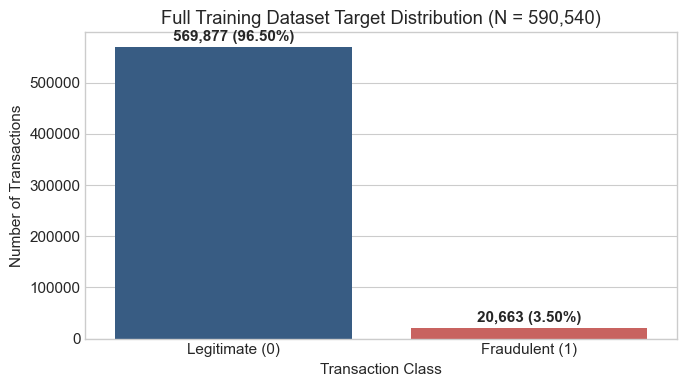

In [10]:
# Memory-conscious full-dataset target distribution calculation
if TRAIN_TRANS_PATH.exists():
    print(f"Reading 'isFraud' from full training file: {TRAIN_TRANS_PATH.resolve()}...")
    
    # Load ONLY the target column across all rows to minimize RAM usage (~4.5 MB)
    full_target_series = pd.read_csv(TRAIN_TRANS_PATH, usecols=['isFraud'])['isFraud']
    
    # Metric calculations across the entire dataset
    total_transactions = len(full_target_series)
    null_target_count = int(full_target_series.isna().sum())
    unique_labels = sorted(full_target_series.dropna().unique().tolist())
    
    legit_count = int((full_target_series == 0).sum())
    fraud_count = int((full_target_series == 1).sum())
    unexpected_count = total_transactions - (legit_count + fraud_count + null_target_count)
    
    legit_pct = (legit_count / total_transactions) * 100 if total_transactions > 0 else 0.0
    fraud_pct = (fraud_count / total_transactions) * 100 if total_transactions > 0 else 0.0
    
    # Summary DataFrame
    full_summary_df = pd.DataFrame({
        'Class Label': [0, 1],
        'Description': ['Legitimate (0)', 'Fraudulent (1)'],
        'Count': [legit_count, fraud_count],
        'Population Share (%)': [round(legit_pct, 4), round(fraud_pct, 4)]
    })
    
    print("=" * 72)
    print("FULL TRAINING DATASET TARGET DISTRIBUTION (POPULATION BASELINE)")
    print("=" * 72)
    print(f"Total Labelled Transactions: {total_transactions:,}")
    print(f"Legitimate Transactions (0): {legit_count:,} ({legit_pct:.4f}%)")
    print(f"Fraudulent Transactions (1): {fraud_count:,} ({fraud_pct:.4f}%)")
    print(f"Missing (NaN) Target Labels: {null_target_count}")
    print(f"Unexpected Target Labels:    {unexpected_count} (Unique labels: {unique_labels})")
    print(f"In-Memory Target Size:       {full_target_series.memory_usage(deep=True) / (1024**2):.2f} MB")
    print("=" * 72)
    display(full_summary_df)
    
    # Visualize full dataset distribution
    plt.figure(figsize=(7, 4))
    palette = ['#2b5c8f', '#d9534f'] if len(unique_labels) == 2 else 'Blues'
    ax = sns.barplot(x=full_summary_df['Description'], y=full_summary_df['Count'], palette=palette)
    plt.title(f"Full Training Dataset Target Distribution (N = {total_transactions:,})")
    plt.ylabel("Number of Transactions")
    plt.xlabel("Transaction Class")
    
    for i, row in full_summary_df.iterrows():
        ax.text(
            i,
            row['Count'] + (max(full_summary_df['Count']) * 0.02),
            f"{row['Count']:,} ({row['Population Share (%)']:.2f}%)",
            ha='center',
            fontweight='bold'
        )
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Dataset file not found at {TRAIN_TRANS_PATH.resolve()}.")